# 03 · Líneas base y modelos candidatos
Experimento de MLflow: `resenas-bancos-ec`. Misma preparación (`src/pipeline.py`), misma validación (`TimeSeriesSplit(5)` sobre el train) y misma métrica (PR-AUC de la clase negativa) para todos.
Ejecutar con *Restart* y luego *Run All*. El conjunto de prueba **no se usa** aquí.

In [1]:
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns, mlflow
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from lightgbm import LGBMClassifier
from src.datos import cargar_obt
from src.pipeline import *
from src.experimento import *
sns.set_theme(style="whitegrid")
df = agregar_features(cargar_obt())
train, test = split_temporal(df, 0.2)          # test no se toca en este notebook
X, y = train[FEATURES], train[TARGET]
FECHA_CORTE = df[FECHA].max().isoformat()
configurar()
print(X.shape, "| % negativa:", round(y.mean()*100, 1), "| corte del snapshot:", FECHA_CORTE)

/usr/local/lib/python3.12/site-packages/snowflake/connector/connection/_connection.py:137: FutureWarning: enable_server_session_keep_alive_auto_detection was not set and defaults to True. In a future version, the default will change to None. Please provide an explicit value: True = check for running async queries before logout (queries are preserved); False/None = always send logout on close (async queries may be terminated by server). Logout behavior can also be overridden with server_session_keep_alive. See the connection parameter docs for more info.
  options = self.config.to_proto_options(


(17358, 6) | % negativa: 46.4 | corte del snapshot: 2026-11-12T01:11:20


## 1. Líneas base (2 corridas)
- **Ingenua:** `DummyClassifier` (prior de la clase).
- **De negocio:** regla de palabras de queja (lo que haría un analista a mano).

In [2]:
limpiar_fase("baseline")
res = []
res.append(correr("baseline-dummy", Pipeline([("modelo", DummyClassifier(strategy="prior"))]),
                  "baseline", "dummy", X, y, {"strategy": "prior"}, FECHA_CORTE))
res.append(correr("baseline-regla-lexico", Pipeline([("modelo", ReglaNegocio())]),
                  "baseline", "regla_negocio", X, y, {"n_palabras_lexico": len(LEXICO_NEG)}, FECHA_CORTE))
pd.DataFrame(res)[["nombre","cv_pr_auc_mean","cv_pr_auc_std","cv_f1_mean","costo_cv_umbral"]].round(4)

/usr/local/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/16 23:32:49 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during de

🏃 View run baseline-dummy at: http://mlflow:5000/#/experiments/2/runs/7f593707473a45d49529db17d73ae1ee
🧪 View experiment at: http://mlflow:5000/#/experiments/2


/usr/local/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/16 23:32:57 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during de

🏃 View run baseline-regla-lexico at: http://mlflow:5000/#/experiments/2/runs/a05a6c4ec8744104b7be9af231188edb
🧪 View experiment at: http://mlflow:5000/#/experiments/2


,nombre,cv_pr_auc_mean,cv_pr_auc_std,cv_f1_mean,costo_cv_umbral
0,baseline-dummy,0.4700,0.1137,0.0872,0.530
1,baseline-regla-lexico,0.7488,0.0662,0.7665,0.787


## 2. Candidatos con hiperparámetros por defecto (4 corridas aquí; la 5.ª familia se agrega en `03b`)

In [3]:
limpiar_fase("candidato")
candidatos = {
    "lineal_regularizado": ("LogisticRegression", LogisticRegression(max_iter=1000), False),
    "bagging":             ("RandomForest",       RandomForestClassifier(random_state=SEED, n_jobs=-1), False),
    "boosting":            ("LightGBM",           LGBMClassifier(random_state=SEED, verbose=-1), False),
    "red_neuronal":        ("MLPClassifier",      MLPClassifier(random_state=SEED), False),
}
for familia, (nombre, modelo, denso) in candidatos.items():
    print("→", nombre)
    res.append(correr(f"candidato-{nombre}", construir_pipeline(modelo, denso=denso), "candidato", familia,
                      X, y, {"modelo": nombre, **{k: str(v) for k, v in modelo.get_params().items() if k in ("C","n_estimators","learning_rate","hidden_layer_sizes","max_iter")}},
                      FECHA_CORTE))

→ LogisticRegression


/usr/local/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/16 23:33:09 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during de

🏃 View run candidato-LogisticRegression at: http://mlflow:5000/#/experiments/2/runs/c91e992e7fc14a1299dbbbc970044f39
🧪 View experiment at: http://mlflow:5000/#/experiments/2
→ RandomForest


/usr/local/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/16 23:33:26 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during de

🏃 View run candidato-RandomForest at: http://mlflow:5000/#/experiments/2/runs/305d8892154342be9387df251d7cef17
🧪 View experiment at: http://mlflow:5000/#/experiments/2
→ LightGBM


/usr/local/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/16 23:33:41 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during de

🏃 View run candidato-LightGBM at: http://mlflow:5000/#/experiments/2/runs/623e64fc99bd4fc887ccc685d9a6c891
🧪 View experiment at: http://mlflow:5000/#/experiments/2
→ MLPClassifier


/usr/local/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/16 23:38:15 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during de

🏃 View run candidato-MLPClassifier at: http://mlflow:5000/#/experiments/2/runs/0c15187efb4c42628b3d909d48173aba
🧪 View experiment at: http://mlflow:5000/#/experiments/2


## 3. Resultados

,train_pr_auc,cv_pr_auc_mean,cv_pr_auc_std,brecha_pr_auc,cv_f1_mean,costo_cv_umbral,umbral_costo,segundos_entrenamiento
nombre,,,,,,,,
candidato-LogisticRegression,0.9667,0.9434,0.0176,0.0234,0.9030,0.1559,0.28,0.7122
candidato-LightGBM,0.9851,0.9405,0.0150,0.0447,0.8982,0.1562,0.13,1.6889
candidato-RandomForest,0.9972,0.9282,0.0213,0.0689,0.8981,0.1728,0.34,2.2986
candidato-MLPClassifier,0.9992,0.9191,0.0290,0.0801,0.8809,0.2342,0.06,66.8065
baseline-regla-lexico,0.7494,0.7488,0.0662,0.0006,0.7665,0.7870,0.05,0.0004
baseline-dummy,0.4642,0.4700,0.1137,-0.0059,0.0872,0.5300,0.05,0.0011


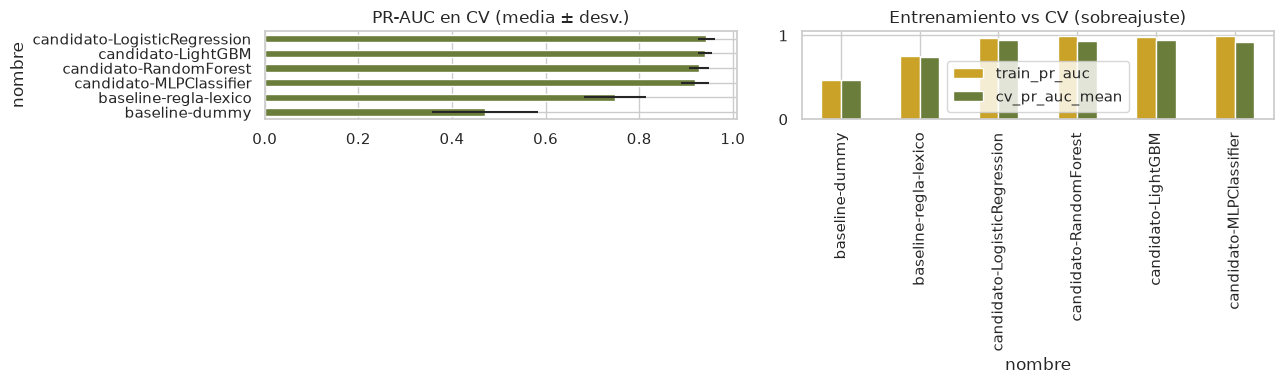

In [4]:
t = pd.DataFrame(res).set_index("nombre")
cols = ["train_pr_auc","cv_pr_auc_mean","cv_pr_auc_std","brecha_pr_auc","cv_f1_mean","costo_cv_umbral","umbral_costo","segundos_entrenamiento"]
display(t[cols].round(4).sort_values("cv_pr_auc_mean", ascending=False))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
t["cv_pr_auc_mean"].sort_values().plot.barh(ax=ax[0], xerr=t["cv_pr_auc_std"].reindex(t["cv_pr_auc_mean"].sort_values().index), color="#6b7d3a")
ax[0].set_title("PR-AUC en CV (media ± desv.)")
t[["train_pr_auc","cv_pr_auc_mean"]].plot.bar(ax=ax[1], color=["#c9a227","#6b7d3a"]); ax[1].set_title("Entrenamiento vs CV (sobreajuste)")
plt.tight_layout(); plt.savefig("/work/docs/figs/candidatos.png", dpi=150); plt.show()

## 4. Diagnóstico (completar con las cifras de la tabla)
- ¿Algún modelo no supera la regla de negocio? → documentarlo como hallazgo.
- Brecha train − CV alta ⇒ sobreajuste (típico de RandomForest con TF-IDF).
- Los 3 mejores por PR-AUC en CV pasan a la fase de *tuning*.